# 05 - Fine-tuning on unlabeled images: does the fix work?

Trained on Kaggle GPUs from **unlabeled** images only:
- outdoor head: frames of 7 KITTI raw drives, none of them a drive of the KITTI val
  selection (checked in the kernel);
- indoor head: RGB of the 795 official NYUv2 train images.

Four variants of DA-V2-S, all scored with identical preprocessing (input height 392):
- **frozen** - the released model;
- **blur-only** - same data, steps and flips, zoom loss off: what fine-tuning alone does
  (an anchor-only run would be the frozen model: student == teacher gives zero gradient);
- **EFT** - zoom self-consistency (in the spirit of Zhong et al., ICCV 2023);
- **EFT+B** - EFT plus blur invariance, against the "blurry = zoomed" shortcut;
- **EFT+B, lambda=3** - with a stronger anchor, to probe the cost on unzoomed images.

DIODE is never used in training. Every comparison is paired (same images), tested with a
Wilcoxon signed-rank test and Holm-corrected over all comparisons.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import analysis as A
import plotstyle as ps

ps.use()
TAB = ROOT / "outputs/tables"
EFT = ROOT / "outputs" / "eft"
# anchor-only is omitted: it is the frozen model (zero loss and gradient at the start)
FT = ["dav2-s-fixed", "dav2-s-blur", "dav2-s-eft", "dav2-s-eftb", "dav2-s-eftb3"]

df = A.load()
df = df[df.model.isin(FT)]
FT = [m for m in FT if m in set(df.model)]
pi = A.per_image(df)
print(pi.groupby(["model", "dataset"]).size().unstack())

dataset       diode-in  diode-out  kitti  nyu
model                                        
dav2-s-blur        200        200    200  200
dav2-s-eft         200        200    200  200
dav2-s-eftb        200        200    200  200
dav2-s-eftb3       200        200    200  200
dav2-s-fixed       200        200    200  200


## Training curves

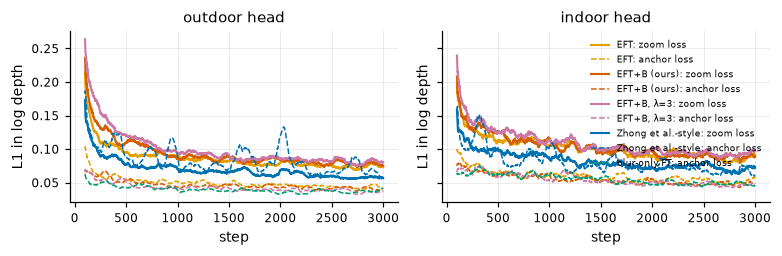

In [2]:
def train_log(tag, dom):
    # the first EFT run wrote train_log_<domain>.csv, later runs train_log_<tag>_<domain>.csv
    for f in (EFT / f"train_log_{tag}_{dom}.csv", EFT / f"train_log_{dom}.csv"):
        if f.exists():
            return pd.read_csv(f)


fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.4), sharey=True)
for ax, dom in zip(axes, ("outdoor", "indoor")):
    for tag, m in (("eft", "dav2-s-eft"), ("eftb", "dav2-s-eftb"), ("eftb3", "dav2-s-eftb3"), ("zhong", "dav2-s-zhong"),
                   ("blur", "dav2-s-blur")):
        log = train_log(tag, dom)
        if log is None:
            continue
        if tag != "blur":
            ax.plot(log.step, log.l_zoom.rolling(100).mean(), color=ps.colour(m), lw=1.4, label=f"{ps.LABEL[m]}: zoom loss")
        ax.plot(log.step, log.l_anchor.rolling(100).mean(), color=ps.colour(m), lw=1, ls="--", label=f"{ps.LABEL[m]}: anchor loss")
    ax.set(title=f"{dom} head", xlabel="step", ylabel="L1 in log depth")
axes[1].legend(fontsize=6)
fig.tight_layout()
ps.save(fig, "figS_eft_training")

## Table 2: frozen vs anchor-only vs EFT vs EFT+B

In [3]:
s = A.summary(pi)
t2 = s.pivot(index="dataset", columns="model", values=["alpha", "absrel1", "absrel3"]).reindex(A.DATASETS)
blur = df[df.kind == "blur"].groupby(["model", "dataset"]).log_ratio_self.apply(
    lambda v: float(np.exp(np.median(np.abs(v))) - 1)).unstack("model")
t2.round(3).to_csv(TAB / "table2_eft.csv")
blur.round(3).to_csv(TAB / "eft_blur_control.csv")
display(t2.round(3))
display((100 * blur).round(1).rename(columns=ps.LABEL))

alpha                                                   \
model     dav2-s-blur dav2-s-eft dav2-s-eftb dav2-s-eftb3 dav2-s-fixed   
dataset                                                                  
kitti           0.821      0.184       0.053        0.068        1.032   
nyu             0.561      0.121       0.067        0.050        0.981   
diode-in        0.442      0.386       0.368        0.353        0.704   
diode-out       0.453      0.389       0.396        0.410        0.649   

              absrel1                                                   \
model     dav2-s-blur dav2-s-eft dav2-s-eftb dav2-s-eftb3 dav2-s-fixed   
dataset                                                                  
kitti           0.160      0.156       0.175        0.173        0.138   
nyu             0.384      0.313       0.301        0.360        0.344   
diode-in        0.404      0.368       0.400        0.432        0.280   
diode-out       0.802      0.877       1.000        0.971        0.731   

              absrel3                                                   
model     dav2-s-blur dav2-s-eft dav2-s-eftb dav2-s-eftb3 dav2-s-fixed  
dataset                                                                 
kitti           0.538      0.158       0.178        0.162        0.665  
nyu             0.298      0.226       0.266        0.293        0.563  
diode-in        0.385      0.364       0.367        0.365        0.558  
diode-out       0.622      0.648       0.676        0.647        0.551

model,blur-only FT,EFT,EFT+B (ours),"EFT+B, λ=3",DA-V2-S (frozen)
dataset,,,,,
diode-in,0.3,0.6,0.4,0.4,1.0
diode-out,0.2,1.5,0.4,0.4,0.6
kitti,0.2,29.6,4.9,6.7,1.1
nyu,0.2,4.2,0.4,0.3,0.7


## Paired tests (Wilcoxon signed-rank, Holm-corrected)
For each dataset and each fine-tuned variant against the frozen model: AbsRel at 1x (does
tuning hurt normal images?), AbsRel at 3x (does it help zoomed ones?), and |alpha|.

In [4]:
def holm(p):
    p = np.asarray(p, float)
    order = np.argsort(p)
    adj = np.empty_like(p)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(p) - rank) * p[i])
        adj[i] = min(1.0, running)
    return adj


tests = []
wide = pi.assign(abs_alpha=pi.alpha.abs()).pivot_table(index=["dataset", "name"], columns="model",
                                                       values=["absrel1", "absrel3", "abs_alpha"])
for ds in A.DATASETS:
    for m in FT[1:]:
        for metric in ("absrel1", "absrel3", "abs_alpha"):
            pair = wide.loc[ds][[(metric, "dav2-s-fixed"), (metric, m)]].dropna()
            if len(pair) < 10:
                continue
            a, b = pair.iloc[:, 0], pair.iloc[:, 1]
            tests.append(dict(dataset=ds, model=m, metric=metric, n=len(pair), frozen=a.mean(), tuned=b.mean(),
                              change=b.mean() - a.mean(), p=wilcoxon(a, b).pvalue))
tests = pd.DataFrame(tests)
tests["p_holm"] = holm(tests.p)
tests["significant"] = tests.p_holm < 0.05
tests.round(4).to_csv(TAB / "eft_paired_tests.csv", index=False)
tests.round(4)

,dataset,model,metric,n,frozen,tuned,change,p,p_holm,significant
0,kitti,dav2-s-blur,absrel1,200,0.1382,0.1598,0.0217,0.0000,0.0000,True
1,kitti,dav2-s-blur,absrel3,200,0.6649,0.5377,-0.1272,0.0000,0.0000,True
2,kitti,dav2-s-blur,abs_alpha,200,1.0721,0.8140,-0.2581,0.0000,0.0000,True
3,kitti,dav2-s-eft,absrel1,200,0.1382,0.1564,0.0182,0.0000,0.0000,True
4,kitti,dav2-s-eft,absrel3,200,0.6649,0.1582,-0.5067,0.0000,0.0000,True
5,kitti,dav2-s-eft,abs_alpha,200,1.0721,0.1849,-0.8871,0.0000,0.0000,True
6,kitti,dav2-s-eftb,absrel1,200,0.1382,0.1748,0.0366,0.0000,0.0000,True
7,kitti,dav2-s-eftb,absrel3,200,0.6649,0.1781,-0.4868,0.0000,0.0000,True
8,kitti,dav2-s-eftb,abs_alpha,200,1.0721,0.0754,-0.9967,0.0000,0.0000,True
9,kitti,dav2-s-eftb3,absrel1,200,0.1382,0.1732,0.0351,0.0000,0.0000,True


## Figure 5: depth ratio and accuracy vs zoom

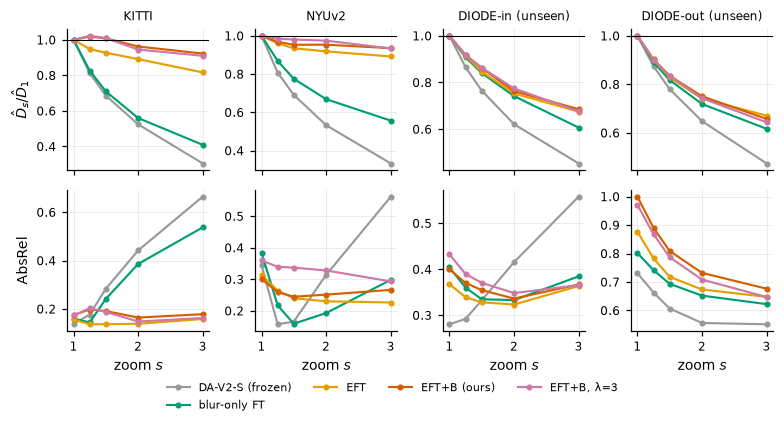

In [5]:
z = df[df.kind == "zoom"]
curve = z.groupby(["model", "dataset", "zoom"]).agg(depth=("log_ratio_self", "median"), absrel=("abs_rel", "mean"),
                                                    s=("s_true", "median")).reset_index()
fig, axes = plt.subplots(2, 4, figsize=(7.2, 3.8), sharex=True)
for k, ds in enumerate(A.DATASETS):
    for m in FT:
        c = curve[(curve.model == m) & (curve.dataset == ds)].sort_values("zoom")
        axes[0, k].plot(c.s, np.exp(c.depth), color=ps.colour(m), lw=1.4, marker="o", ms=3, label=ps.LABEL[m])
        axes[1, k].plot(c.s, c.absrel, color=ps.colour(m), lw=1.4, marker="o", ms=3)
    axes[0, k].axhline(1, color="k", lw=0.7)
    axes[0, k].set_title(A.PRETTY_DS[ds] + (" (unseen)" if ds.startswith("diode") else ""), fontsize=8)
    axes[1, k].set_xlabel("zoom $s$")
axes[0, 0].set_ylabel(r"$\hat D_s/\hat D_1$")
axes[1, 0].set_ylabel("AbsRel")
h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(rect=(0, 0.06, 1, 1))
ps.save(fig, "fig5_finetuning")